# Explore HRRR-AK near Lone Island

**Purpose:** learn to inspect a cleaned NetCDF, understand its variables and metadata, select a nearby grid cell, and plot weather time series.

Run **`3_clean_hrrrak_netcdf.ipynb`** first. This notebook opens its `_crs.nc` output and uses the saved projection; it does not repeat cleaning or require the original GRIB files.

| Sample | Meaning |
| :--- | :--- |
| April 1–7, 2019 initializations | 168 forecast records on a 3 × 3 grid |
| Leads 5, 6, and 7 hours | Valid-time coverage extends into April 8 |
| Reference 58.721963, −136.295474 | User-provided map-pin screenshot; station location unconfirmed |

Select **glacierbay**, then **Run All**. Figures are embedded by `%matplotlib inline`. Save with outputs for GitHub. This notebook reads local data without downloads and leaves the input file unchanged; the selected point series remains in memory.

## 1. Import tools

In [1]:
%matplotlib inline
from pathlib import Path
import sys

if Path(sys.prefix).name != "glacierbay":
    raise RuntimeError("Select the glacierbay kernel, restart, and run all cells.")

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import rioxarray  # Reads the CRS saved by notebook 3.
from pyproj import CRS, Transformer

print(f"Python: {sys.executable}")

Python: /home/cassie/programs/miniforge3/envs/glacierbay/bin/python


## 2. Open the cleaned NetCDF

A **Dataset** holds several **DataArrays**, each with named dimensions, coordinates, values, and attributes. `decode_coords="all"` recognizes the saved CRS grid-mapping coordinate. We load this small file into memory and close its file handle.

Inspect the summary: which dimension describes forecasts? Which describe space? Both projected `x`/`y` (meters) and geographic latitude/longitude (degrees) should now be present.

In [2]:
# Resolve paths from the project folder or its parent workspace.
project_dir = Path.cwd()
if not (project_dir / "hrrrak").is_dir():
    project_dir = project_dir / "glacierbay_alaska"
data_dir = project_dir / "hrrrak"
input_path = data_dir / "lone_island_small_hrrrak_20190401_20190407_crs.nc"

if not input_path.is_file():
    raise FileNotFoundError("Run 3_clean_hrrrak_netcdf.ipynb first to create the cleaned NetCDF.")

with xr.open_dataset(input_path, decode_coords="all", decode_timedelta=True) as opened:
    ds = opened.load()
print(f"Opened: {input_path.resolve()}")
display(ds)

# Use the saved native CRS; assigning a different EPSG code would mislabel this grid.
clean = ds
if clean.rio.crs is None:
    raise ValueError("Cleaned file has no CRS. Rerun notebook 3.")
native_crs = CRS.from_user_input(clean.rio.crs)
to_native = Transformer.from_crs(native_crs.geodetic_crs, native_crs, always_xy=True)
print("Saved native CRS:", clean.rio.crs)
print("Projected grid spacing (m):", clean.rio.resolution())

Opened: /home/cassie/python/repos/glacierbay_alaska/hrrrak/lone_island_small_hrrrak_20190401_20190407_crs.nc


<xarray.Dataset> Size: 117kB
Dimensions:                  (time: 168, y: 3, x: 3)
Coordinates:
  * time                     (time) datetime64[ns] 1kB 2019-04-01T05:00:00 .....
    forecast_reference_time  (time) datetime64[ns] 1kB 2019-04-01 ... 2019-04...
    forecast_period          (time) timedelta64[ns] 1kB 05:00:00 ... 07:00:00
    source_file              (time) <U42 28kB 'hrrr.20190401/hrrr.t00z.wrfsfc...
  * y                        (y) float64 24B -3.331e+06 -3.328e+06 -3.325e+06
  * x                        (x) float64 24B -7.705e+04 -7.405e+04 -7.105e+04
    latitude                 (y, x) float64 72B 58.69 58.69 ... 58.74 58.75
    longitude                (y, x) float64 72B -136.3 -136.3 ... -136.3 -136.2
    spatial_ref              int64 8B 0
Data variables: (12/14)
    temp                     (time, y, x) float32 6kB 283.6 283.8 ... 280.1
    rh                       (time, y, x) float32 6kB 50.7 50.2 ... 90.9 89.4
    u10                      (time, y, x) float32 6kB 3.406 4.594 ... -4.852
    v10                      (time, y, x) float32 6kB 2.294 0.6693 ... 4.817
    pressure                 (time, y, x) float32 6kB 1.031e+05 ... 9.982e+04
    temp_surface             (time, y, x) float32 6kB 281.3 281.5 ... 282.6
    ...                       ...
    lwrad                    (time, y, x) float32 6kB 262.1 262.5 ... 332.7
    precip_rate              (time, y, x) float32 6kB 0.0 0.0 ... 0.00019
    precip_total             (time, y, x) float32 6kB 0.0 0.0 ... 3.795 3.283
    snowdepth                (time, y, x) float32 6kB 0.0 0.0 0.0 ... 0.0 0.0
    swe                      (time, y, x) float32 6kB 0.0 0.0 0.0 ... 0.0 0.0
    wind                     (time, y, x) float32 6kB 4.107 4.642 ... 6.837
Attributes: (12/18)
    long_name:                  2 metre temperature
    units:                      K
    standard_name:              air_temperature
    title:                      HRRR-AK Lone Island small-domain forecasts
    model:                      HRRR-AK
    time_zone:                  UTC
    ...                         ...
    missing_expected_files:     0
    partial_download:           0
    missing_file_list:          
    history:                    Created 2026-10-15T11:30:53.246850+00:00 by 2...
    processing_notes:           Native units retained. Precipitation total st...
    crs_provenance:             Native projection restored from hrrr.t00z.wrf...

Saved native CRS: PROJCS["unknown",GEOGCS["unknown",DATUM["unknown",SPHEROID["unknown",6371229,0]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433]],PROJECTION["Polar_Stereographic"],PARAMETER["latitude_of_origin",60],PARAMETER["central_meridian",-135],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",SOUTH],AXIS["Northing",SOUTH]]
Projected grid spacing (m): (3000.000000000269, 3000.0000000006985)


## 3. Inspect variables, coordinates, and attributes

- `ds.data_vars`: meteorological arrays such as `temp` and `wind`.
- `ds.coords`: labels and locations, including valid time, forecast lead, and 2-D latitude/longitude.
- `.attrs`: descriptive metadata; inspect both the dataset and individual variables.

**Read units before calculations.** `temp` is 2 m air temperature in Kelvin; `temp_surface` is a different quantity. Snow water equivalent and precipitation totals use mass per area here, rather than meters. GRIB attributes describe measurement height and time statistic.

In [3]:
# Summarize what is available before choosing a field to plot.
variable_table = pd.DataFrame([
    {"variable": name, "description": value.attrs.get("long_name", ""),
     "units": value.attrs.get("units", ""), "dimensions": str(value.dims),
     "GRIB_time_statistic": value.attrs.get("GRIB_stepType", "derived")}
    for name, value in ds.data_vars.items()
])
display(variable_table)
display(pd.DataFrame([{"coordinate": name, "dimensions": str(value.dims),
                       "shape": str(value.shape), "units": value.attrs.get("units", "")}
                      for name, value in ds.coords.items()]))
print("Dataset attributes:")
display(pd.Series(ds.attrs, dtype=object).to_frame("value"))
print("Air-temperature attributes (try ds.wind.attrs next):")
display(pd.Series(ds.temp.attrs, dtype=object).to_frame("value"))

,variable,description,units,dimensions,GRIB_time_statistic
0,temp,2 metre temperature,K,"('time', 'y', 'x')",instant
1,rh,2 metre relative humidity,%,"('time', 'y', 'x')",instant
2,u10,10 metre U wind component,m s**-1,"('time', 'y', 'x')",instant
3,v10,10 metre V wind component,m s**-1,"('time', 'y', 'x')",instant
4,pressure,Surface pressure,Pa,"('time', 'y', 'x')",instant
5,temp_surface,Temperature,K,"('time', 'y', 'x')",instant
6,terrain_height,Orography,m,"('time', 'y', 'x')",instant
7,swrad,Surface downward short-wave radiation flux,W m**-2,"('time', 'y', 'x')",instant
8,lwrad,Surface downward long-wave radiation flux,W m**-2,"('time', 'y', 'x')",instant
9,precip_rate,Precipitation rate,kg m**-2 s**-1,"('time', 'y', 'x')",instant


,coordinate,dimensions,shape,units
0,time,"('time',)","(168,)",
1,latitude,"('y', 'x')","(3, 3)",degrees_north
2,longitude,"('y', 'x')","(3, 3)",degrees_east
3,forecast_reference_time,"('time',)","(168,)",
4,forecast_period,"('time',)","(168,)",
5,source_file,"('time',)","(168,)",
6,x,"('x',)","(3,)",metre
7,y,"('y',)","(3,)",metre
8,spatial_ref,(),(),


Dataset attributes:


,value
long_name,2 metre temperature
units,K
standard_name,air_temperature
title,HRRR-AK Lone Island small-domain forecasts
model,HRRR-AK
time_zone,UTC
reference_latitude,58.721963
reference_longitude,-136.295474
coordinate_provenance,User-provided map-pin screenshot; exact statio...
initialization_date_start,2019-04-01


Air-temperature attributes (try ds.wind.attrs next):


,value
GRIB_paramId,167
GRIB_dataType,fc
GRIB_numberOfPoints,9
GRIB_typeOfLevel,heightAboveGround
GRIB_stepUnits,1
GRIB_stepType,instant
GRIB_gridType,polar_stereographic
GRIB_NV,0
GRIB_cfName,air_temperature
GRIB_cfVarName,t2m


## 4. Understand the forecast timeline

A dataset that opens successfully still needs inspection. Look for missing values, unexpected ranges, duplicate forecast records, and time gaps. These checks report what exists; they do not fill gaps or remove unusual weather.

| Coordinate | Meaning |
| :--- | :--- |
| `forecast_reference_time` | Forecast initialization, in UTC |
| `forecast_period` | Lead time after initialization |
| `time` | UTC valid time: initialization + lead |

Time values are stored without a pandas time-zone suffix, but their documented convention is UTC. Do not treat them as Alaska local time. Duplicate **valid times** can represent different forecasts; duplicate initialization/lead pairs would be a problem.

In [4]:
# Report ranges in native units and count missing values.
display(pd.DataFrame([
    {"variable": name, "units": value.attrs.get("units", ""),
     "minimum": float(value.min()), "maximum": float(value.max()),
     "missing": int(value.isnull().sum())}
    for name, value in ds.data_vars.items()
]))
timing = pd.DataFrame({
    "initialization_UTC": ds.forecast_reference_time.values,
    "lead_hours": ds.forecast_period.values / np.timedelta64(1, "h"),
    "valid_time_UTC": ds.time.values,
})
assert not timing.duplicated(["initialization_UTC", "lead_hours"]).any()
assert np.array_equal(ds.time.values, ds.forecast_reference_time.values + ds.forecast_period.values)
assert pd.Index(ds.time.values).is_monotonic_increasing
print("Spatial shape:", {key: ds.sizes[key] for key in ("y", "x")})
print("Duplicate valid times:", timing.valid_time_UTC.duplicated().sum())
print("Time-step counts (inspect gaps):")
print(timing.valid_time_UTC.diff().value_counts())
display(timing.head(10))

,variable,units,minimum,maximum,missing
0,temp,K,275.552246,285.607239,0
1,rh,%,40.299999,99.900002,0
2,u10,m s**-1,-9.363325,7.411646,0
3,v10,m s**-1,-5.284840,11.473278,0
4,pressure,Pa,98840.000000,103060.000000,0
5,temp_surface,K,281.058533,282.654449,0
6,terrain_height,m,0.000000,6.218750,0
7,swrad,W m**-2,0.000000,606.000000,0
8,lwrad,W m**-2,246.000000,337.899994,0
9,precip_rate,kg m**-2 s**-1,0.000000,0.001320,0


Spatial shape: {'y': 3, 'x': 3}
Duplicate valid times: 0
Time-step counts (inspect gaps):
valid_time_UTC
0 days 01:00:00    167
Name: count, dtype: int64


,initialization_UTC,lead_hours,valid_time_UTC
0,2019-04-01 00:00:00,5.0,2019-04-01 05:00:00
1,2019-04-01 00:00:00,6.0,2019-04-01 06:00:00
2,2019-04-01 00:00:00,7.0,2019-04-01 07:00:00
3,2019-04-01 03:00:00,5.0,2019-04-01 08:00:00
4,2019-04-01 03:00:00,6.0,2019-04-01 09:00:00
5,2019-04-01 03:00:00,7.0,2019-04-01 10:00:00
6,2019-04-01 06:00:00,5.0,2019-04-01 11:00:00
7,2019-04-01 06:00:00,6.0,2019-04-01 12:00:00
8,2019-04-01 06:00:00,7.0,2019-04-01 13:00:00
9,2019-04-01 09:00:00,5.0,2019-04-01 14:00:00


## 5. Find the nearest grid cell to Lone Island

The map-pin coordinates are an approximate reference, not verified station metadata. We interpret their longitude/latitude numerically on the model sphere for this preliminary selection; confirm their original datum before precise station matching.

Use the full 2-D geographic arrays to compute surface distance to every grid-cell center. `.sel(latitude=..., longitude=..., method="nearest")` does not directly work with these 2-D coordinates. Instead, find the nearest row/column, then use `.isel()`.

**Nearest cell ≠ observation at that point.** The model represents an area; coastal land/water differences and terrain can matter even for a nearby cell.

In [5]:
reference_lat, reference_lon = 58.721963, -136.295474
model_geod = native_crs.get_geod()  # Uses the model Earth shape saved in the CRS.
_, _, distances_m = model_geod.inv(
    np.full(clean.longitude.shape, reference_lon),
    np.full(clean.latitude.shape, reference_lat),
    clean.longitude.values, clean.latitude.values,
)
row, column = np.unravel_index(np.nanargmin(distances_m), distances_m.shape)
point = clean.isel(y=int(row), x=int(column)).copy()
point.attrs.update(
    selection="Nearest grid-cell center by geodesic distance on model sphere",
    reference_latitude=reference_lat, reference_longitude=reference_lon,
    selected_grid_row=int(row), selected_grid_column=int(column),
    reference_distance_m=float(distances_m[row, column]),
    station_location_status="Unconfirmed; selection uses island map-pin reference",
)
display(pd.DataFrame([{
    "row": row, "column": column,
    "grid_latitude": float(point.latitude), "grid_longitude": float(point.longitude),
    "distance_to_reference_m": float(distances_m[row, column]),
    "model_terrain_height_m": float(point.terrain_height.isel(time=0)),
}]))
display(point.temp)

,row,column,grid_latitude,grid_longitude,distance_to_reference_m,model_terrain_height_m
0,1,1,58.717805,-136.274748,1282.863423,0.0


<xarray.DataArray 'temp' (time: 168)> Size: 672B
array([283.5113 , 283.53168, 283.47272, 283.938  , 283.87744, 284.03586,
       283.9527 , 284.0382 , 284.1181 , 283.83673, 283.85883, 283.93268,
       283.76495, 284.0962 , 284.41656, 284.35135, 284.51263, 284.66382,
       284.5817 , 284.68854, 284.78302, 284.94073, 284.72754, 284.72345,
       284.85724, 284.81052, 284.82916, 284.8095 , 284.75452, 284.69647,
       284.3519 , 284.12894, 283.96442, 283.5998 , 283.48468, 283.3309 ,
       282.40005, 282.3199 , 282.3366 , 282.32834, 282.3423 , 282.6416 ,
       282.90607, 283.05368, 283.17136, 283.16327, 283.07724, 282.96124,
       283.24683, 283.0559 , 282.9117 , 282.55704, 282.26804, 281.87143,
       280.77673, 280.71262, 280.68527, 279.90344, 279.9359 , 280.03375,
       279.41028, 279.2848 , 279.4721 , 279.16785, 279.15125, 279.25717,
       278.91858, 279.25708, 279.30426, 278.85828, 278.55887, 278.45395,
       278.3111 , 277.48206, 277.12952, 277.1587 , 276.911  , 276.70453,
       276.67444, 276.30646, 276.07   , 276.1556 , 276.23975, 276.1647 ,
       276.23328, 276.32153, 276.38312, 276.24088, 276.28662, 276.31314,
       276.2596 , 276.33524, 276.68893, 277.04102, 277.182  , 277.44287,
       277.5391 , 277.90558, 278.1074 , 277.9498 , 278.2069 , 278.34995,
       277.89697, 277.32544, 277.0152 , 277.04175, 277.1775 , 277.30212,
       277.71844, 278.03104, 278.4982 , 278.43225, 278.90656, 279.23273,
       279.3827 , 279.8185 , 279.95312, 278.7327 , 279.21353, 279.49463,
       279.97845, 280.09155, 279.8614 , 279.84375, 280.19067, 280.0571 ,
       279.44913, 280.07294, 280.59464, 280.37646, 280.31238, 280.11713,
       278.78088, 278.6105 , 278.61697, 278.71146, 279.01315, 279.2442 ,
       279.98944, 280.1673 , 280.27722, 280.32724, 280.2691 , 280.36475,
       280.42966, 280.53723, 280.67804, 280.8692 , 280.81067, 280.81235,
       280.34326, 280.109  , 279.89825, 280.02045, 280.45758, 280.16797,
       279.1634 , 279.34717, 278.99274, 278.35223, 279.48193, 279.88373,
       280.4476 , 281.24884, 281.56183, 281.6181 , 280.22345, 280.34225],
      dtype=float32)
Coordinates:
  * time                     (time) datetime64[ns] 1kB 2019-04-01T05:00:00 .....
    forecast_reference_time  (time) datetime64[ns] 1kB 2019-04-01 ... 2019-04...
    forecast_period          (time) timedelta64[ns] 1kB 05:00:00 ... 07:00:00
    source_file              (time) <U42 28kB 'hrrr.20190401/hrrr.t00z.wrfsfc...
    latitude                 float64 8B 58.72
    longitude                float64 8B -136.3
    x                        float64 8B -7.405e+04
    y                        float64 8B -3.328e+06
    spatial_ref              int64 8B 0
Attributes: (12/18)
    GRIB_paramId:                    167
    GRIB_dataType:                   fc
    GRIB_numberOfPoints:             9
    GRIB_typeOfLevel:                heightAboveGround
    GRIB_stepUnits:                  1
    GRIB_stepType:                   instant
    ...                              ...
    GRIB_name:                       2 metre temperature
    GRIB_shortName:                  2t
    GRIB_units:                      K
    long_name:                       2 metre temperature
    units:                           K
    standard_name:                   air_temperature

## 6. Plot the grid and the selected location

The left panel uses native projected meters; the right uses the geographic location of each cell center. Both show the **same first forecast**. No basemap or reprojection is required.

Temperature is converted to Celsius for display; the original `temp` remains in Kelvin. Notice whether the nearest cell center lands exactly on the reference point.

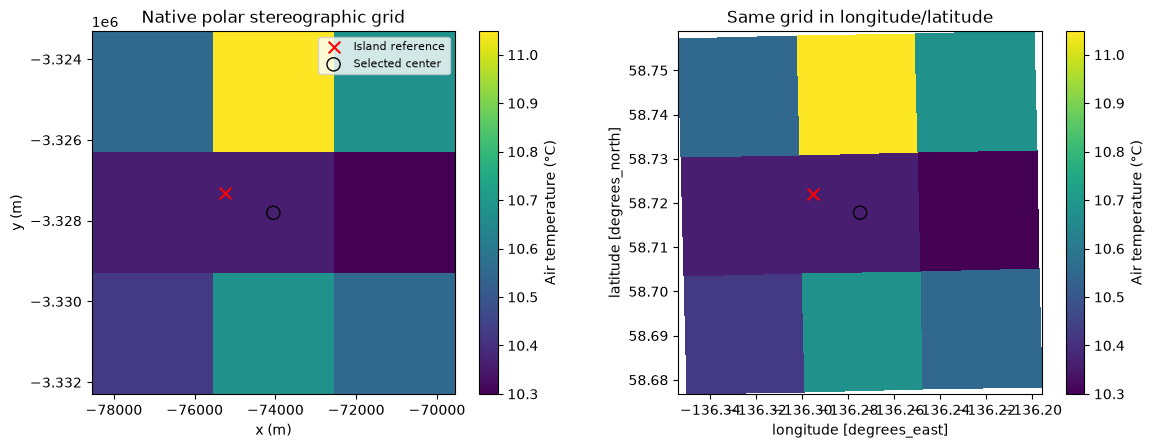

In [6]:
# Create a derived display field with explicit units; preserve the original temperature.
first_c = clean.temp.isel(time=0) - 273.15
first_c.attrs = {"long_name": "2 m air temperature", "units": "degC"}
reference_x, reference_y = to_native.transform(reference_lon, reference_lat)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
first_c.plot(ax=axes[0], x="x", y="y", cbar_kwargs={"label": "Air temperature (°C)"})
axes[0].scatter(reference_x, reference_y, marker="x", color="red", s=70, label="Island reference")
axes[0].scatter(float(point.x), float(point.y), marker="o", facecolors="none", edgecolors="black", s=90, label="Selected center")
axes[0].set_aspect("equal")
axes[0].set_title("Native polar stereographic grid")
axes[0].set_xlabel("x (m)"); axes[0].set_ylabel("y (m)")
axes[0].legend(fontsize=8)
first_c.plot(ax=axes[1], x="longitude", y="latitude", cbar_kwargs={"label": "Air temperature (°C)"})
axes[1].scatter(reference_lon, reference_lat, marker="x", color="red", s=70)
axes[1].scatter(float(point.longitude), float(point.latitude), marker="o", facecolors="none", edgecolors="black", s=90)
axes[1].set_aspect(1 / np.cos(np.deg2rad(reference_lat)))
axes[1].set_title("Same grid in longitude/latitude")
fig.tight_layout()
plt.show()

## 7. Plot the temperature time series

After selecting a spatial cell, the temperature has only a time dimension. Inspect the first records, then plot Celsius against **valid time in UTC**.

Different initialization/lead pairs are different forecasts. Here we color points by lead time and leave any duplicate valid times intact. This sample's leads interleave to provide hourly valid times; the combined line switches between forecast runs. It is not a single forecast trajectory or a station record.

,valid_time_UTC,initialization_UTC,lead_hours,air_temperature_C
0,2019-04-01 05:00:00,2019-04-01 00:00:00,5.0,10.361298
1,2019-04-01 06:00:00,2019-04-01 00:00:00,6.0,10.381683
2,2019-04-01 07:00:00,2019-04-01 00:00:00,7.0,10.322723
3,2019-04-01 08:00:00,2019-04-01 03:00:00,5.0,10.787994
4,2019-04-01 09:00:00,2019-04-01 03:00:00,6.0,10.727448
5,2019-04-01 10:00:00,2019-04-01 03:00:00,7.0,10.885864
6,2019-04-01 11:00:00,2019-04-01 06:00:00,5.0,10.802704
7,2019-04-01 12:00:00,2019-04-01 06:00:00,6.0,10.888214
8,2019-04-01 13:00:00,2019-04-01 06:00:00,7.0,10.968109
9,2019-04-01 14:00:00,2019-04-01 09:00:00,5.0,10.686737


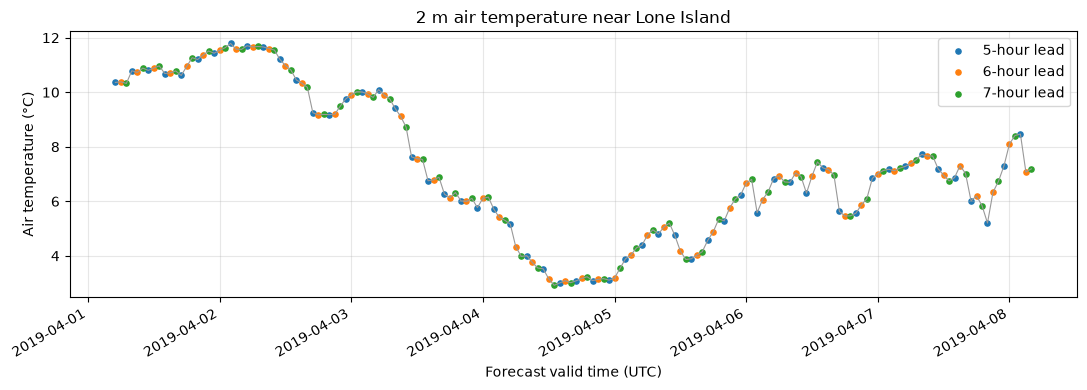

In [7]:
point_temperature_c = point.temp - 273.15
point_temperature_c.attrs = {"long_name": "2 m air temperature", "units": "degC"}
lead_hours = point.forecast_period.values / np.timedelta64(1, "h")
table = pd.DataFrame({
    "valid_time_UTC": point.time.values,
    "initialization_UTC": point.forecast_reference_time.values,
    "lead_hours": lead_hours, "air_temperature_C": point_temperature_c.values,
})
display(table.head(10))
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(point.time.values, point_temperature_c.values, color="0.6", linewidth=0.8)
for lead in np.unique(lead_hours):
    mask = lead_hours == lead
    ax.scatter(point.time.values[mask], point_temperature_c.values[mask], s=14, label=f"{lead:g}-hour lead")
ax.set(title="2 m air temperature near Lone Island", xlabel="Forecast valid time (UTC)", ylabel="Air temperature (°C)")
ax.grid(alpha=0.3)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## 8. Your turn: explore beyond air temperature

Choose one variable from the table in Step 3. Start with **relative humidity (`rh`)**, **wind speed (`wind`)**, or **surface pressure (`pressure`)**. Change `variable_name` below and rerun the cell.

1. Read its attributes. What are its units, measurement height, and time statistic?
2. Describe its minimum, maximum, and missing-value count at the selected cell.
3. Plot it. Can you find a daily pattern or a weather event? Compare the timing with temperature.
4. Select a different nearby grid cell by row/column. How does the series change? Could terrain or water explain differences?
5. Compare `temp` with `temp_surface`. Why might air and surface temperatures differ?

> **Precipitation challenge:** `precip_total` accumulates **from each initialization to valid time**. Consecutive records can come from different initializations and different leads. Do not sum these overlapping totals or difference the combined series as though they were hourly precipitation. Inspect initialization and lead times first. `precip_rate` is an instantaneous rate in the units stored in its attributes.

For radiation, check the time statistic rather than assuming a daily total. For `u10` and `v10`, investigate the GRIB wind-component reference frame before interpreting direction; this notebook does not rotate winds.

Attributes for rh:


,value
GRIB_paramId,260242
GRIB_dataType,fc
GRIB_numberOfPoints,9
GRIB_typeOfLevel,heightAboveGround
GRIB_stepUnits,1
GRIB_stepType,instant
GRIB_gridType,polar_stereographic
GRIB_NV,0
GRIB_cfName,relative_humidity
GRIB_cfVarName,r2


Min: 48.8; max: 98.5; missing: 0


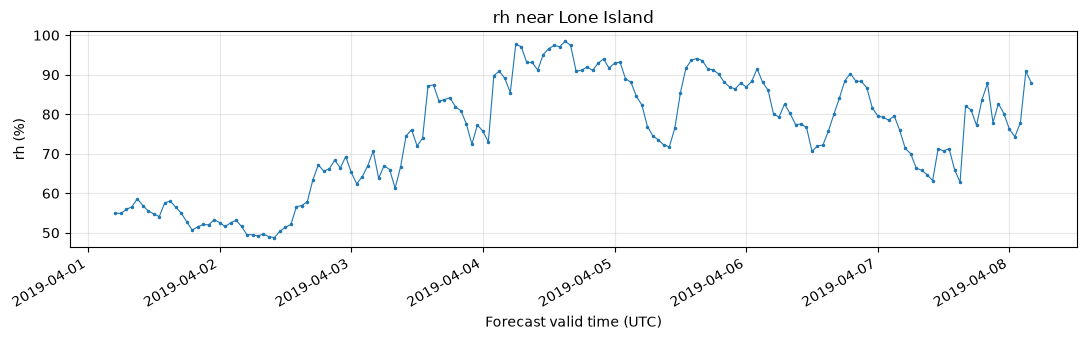

In [8]:
# Student exercise: choose another field; the label follows its stored units.
variable_name = "rh"
values = point[variable_name]
print(f"Attributes for {variable_name}:")
display(pd.Series(values.attrs, dtype=object).to_frame("value"))
print(f"Min: {float(values.min()):.3g}; max: {float(values.max()):.3g}; missing: {int(values.isnull().sum())}")
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(point.time.values, values.values, marker=".", markersize=3, linewidth=0.8)
ax.set(title=f"{variable_name} near Lone Island", xlabel="Forecast valid time (UTC)",
       ylabel=f"{variable_name} ({values.attrs.get('units', 'units not specified')})")
ax.grid(alpha=0.3)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

### Record your findings

Replace these prompts with a few sentences:

- Variable and units explored:
- A pattern or event you noticed:
- Difference from air temperature:
- A metadata or quality question to resolve:
- What you would check before comparing this model series with station observations:

Save the notebook with your outputs and notes so another researcher can follow your work on GitHub.